# Demo: load and visualize dataset by resolution & split
This notebook demonstrates how to load a single sample from the generated dataset for a specific resolution and split, and visualize the full image and the three tensor layers:

- Elevation (normalized float32) ✅
- Start / End markers (marker channel: -1 background, 0=start, 1=end) ✅
- Obstacles mask (binary) ✅

In [1]:
import datasets
import numpy as np
import matplotlib.pyplot as plt
from passage.visualization import tensor_to_image
from passage.utils import decode_tensor_blob

/shared/home/geoffrey.delhomme.e/projects/PASSAGE/passage/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configuration: update these paths if needed
RESOLUTION = 256
SPLIT = "train"  # train / validation / test / calibration

In [3]:
print(f"Resolution: {RESOLUTION}, Split: {SPLIT}")

Resolution: 256, Split: train


In [ ]:
ds = datasets.load_dataset(
    "geoffrey-g-delhomme/passage",
    name=f"{RESOLUTION}x{RESOLUTION}",
)

Generating train split: 14 examples [00:00, 388.20 examples/s]
Generating calibration split: 2 examples [00:00, 95.66 examples/s]
Generating validation split: 2 examples [00:00, 95.41 examples/s]
Generating test split: 2 examples [00:00, 85.31 examples/s]


In [6]:
sample = ds[SPLIT][np.random.randint(len(ds[SPLIT]))]
sample.keys()

dict_keys(['id', 'tensor', 'path_free', 'path_obstacles', 'metadata'])

In [7]:
if "image" in sample.keys():
    plt.imshow(sample["image"])
    plt.axis("off")
    plt.tight_layout()

In [8]:
path_free = sample["path_free"]
path_obstacles = sample["path_obstacles"]
metadata = sample["metadata"]
metadata

{'index': 4,
 'resolution': 256,
 'split': 'train',
 'target_elevation': None,
 'calibration': {'min': -430.0, 'max': 8767.0},
 'tile': {'source': {'lat': 31, 'lon': 80, 'name': 'N031E080'},
  'stats': {'min_elevation': 3837.0, 'max_elevation': 6244.0},
  'used': [{'lat': 32, 'lon': 79, 'name': 'N032E079'},
   {'lat': 32, 'lon': 80, 'name': 'N032E080'},
   {'lat': 32, 'lon': 81, 'name': 'N032E081'},
   {'lat': 31, 'lon': 79, 'name': 'N031E079'},
   {'lat': 31, 'lon': 80, 'name': 'N031E080'},
   {'lat': 31, 'lon': 81, 'name': 'N031E081'},
   {'lat': 30, 'lon': 79, 'name': 'N030E079'},
   {'lat': 30, 'lon': 80, 'name': 'N030E080'},
   {'lat': 30, 'lon': 81, 'name': 'N030E081'}],
  'overlapping': [{'lat': 31, 'lon': 79, 'name': 'N031E079'},
   {'lat': 31, 'lon': 80, 'name': 'N031E080'}]},
 'crop': {'min_elevation': 3790.0,
  'max_elevation': 4517.0,
  'target_elevation': 3872.04736328125,
  'center': {'lat': 31.370277404785156, 'lon': 79.97333526611328},
  'top_left': {'lat': 31.405834197

**NOTE**: Be careful, in order to optimize storage, tensors are saved in **compressed** format. They need to be uncompressed using `decode_tensor_blob` function!

In [ ]:
tensor = decode_tensor_blob(sample["tensor"], (RESOLUTION, RESOLUTION, 3))
print("tensor.shape:", tensor.shape, "dtype:", tensor.dtype)

elevation = (
    tensor[:, :, 0] * (metadata["calibration"]["max"] - metadata["calibration"]["min"]) + metadata["calibration"]["min"]
)
marker = tensor[:, :, 1]
obstacles = tensor[:, :, 2]

print("Elevation min/max:", float(elevation.min()), float(elevation.max()))
print("Marker unique values:", np.unique(marker)[:10])
print("Obstacles unique values:", np.unique(obstacles)[:10])

tensor.shape: (256, 256, 3) dtype: float32
Elevation min/max: 3790.0 4517.00048828125
Marker unique values: [-1.  0.  1.]
Obstacles unique values: [0. 1.]


In [10]:
img_bgr = tensor_to_image(tensor)
img_rgb = img_bgr[:, :, ::-1]

2026-01-28 15:05:45.519 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.4588, max=0.5379
2026-01-28 15:05:45.520 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-28 15:05:45.528 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d


2026-01-28 15:05:45.587 | DEBUG    | passage.visualization:tensor_to_image:52 - tensor_to_image: elevation BEFORE normalization: min=0.4588, max=0.5379
2026-01-28 15:05:45.588 | DEBUG    | passage.visualization:tensor_to_image:98 - tensor_to_image: elevation AFTER normalization: min=0.0000, max=1.0000
2026-01-28 15:05:45.591 | DEBUG    | passage.visualization:tensor_to_image:134 - tensor_to_image: obst_count=%d, path_count=%d, start_count=%d, end_count=%d


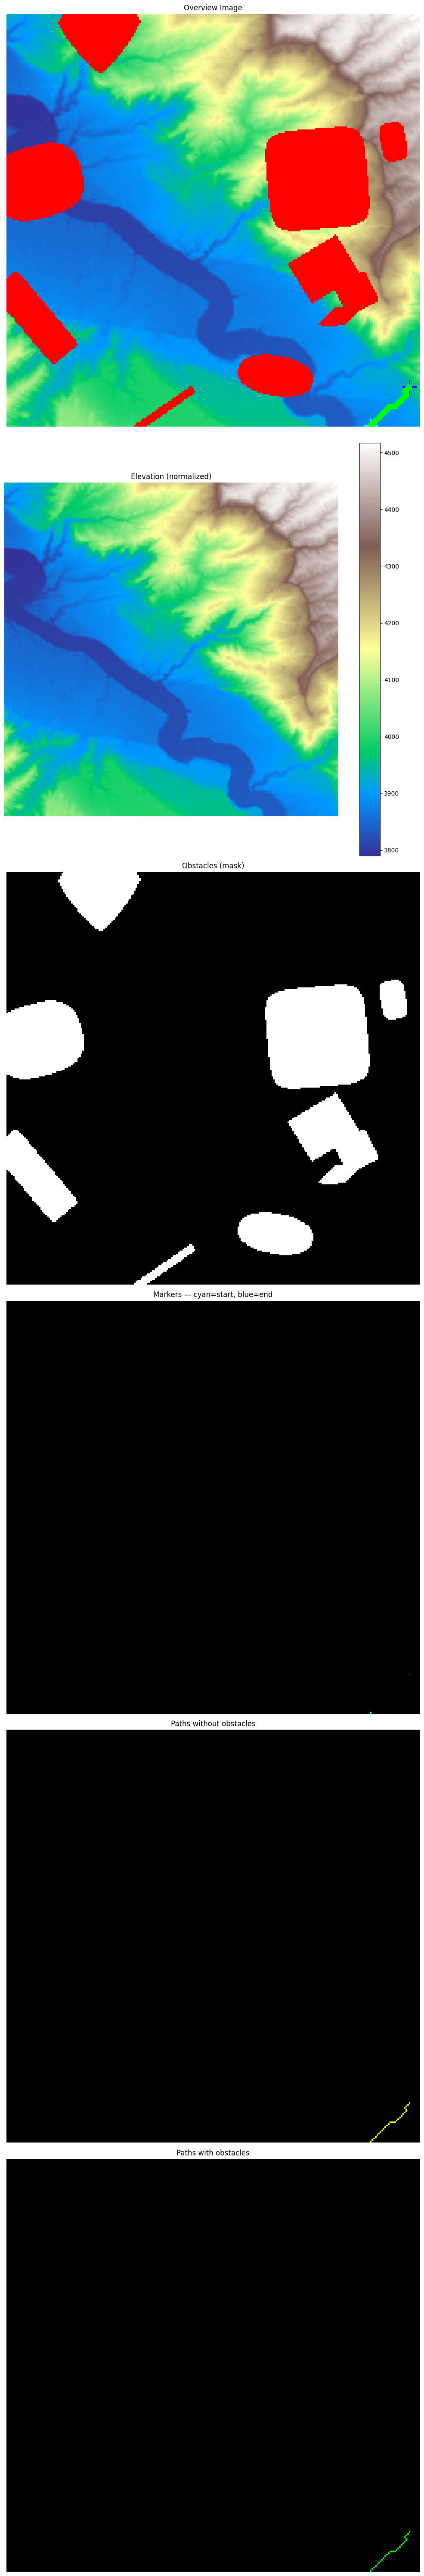

In [11]:
# Visualize each channel separately
fig, axes = plt.subplots(6, figsize=(10, 60))

ax = axes[0]
img_bgr = tensor_to_image(tensor, path_free, path_obstacles)
img_rgb = img_bgr[:, :, ::-1]
ax.imshow(img_rgb)
ax.set_title("Overview Image")
ax.axis("off")

ax = axes[1]
im = ax.imshow(elevation, cmap="terrain")
plt.colorbar(im, ax=ax)
ax.set_title("Elevation (normalized)")
ax.axis("off")

ax = axes[2]
ax.imshow(obstacles, cmap="gray")
ax.set_title("Obstacles (mask)")
ax.axis("off")

ax = axes[3]
# Show start/end markers: start=0 (cyan-ish), end=1 (red-ish)
start_mask = marker == 0.0
end_mask = marker == 1.0
combined = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
combined[start_mask] = [0, 255, 255]
combined[end_mask] = [0, 0, 255]
ax.imshow(combined)
ax.set_title("Markers — cyan=start, blue=end")
ax.axis("off")

ax = axes[4]
paths = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
for x, y in path_free:
    paths[x, y] = [255, 255, 0]  # yellow for free path
ax.imshow(paths)
ax.set_title("Paths without obstacles")
ax.axis("off")

ax = axes[5]
paths = np.zeros((marker.shape[0], marker.shape[1], 3), dtype=np.uint8)
for x, y in path_obstacles:
    paths[x, y] = [0, 255, 0]  # green for obstacle path
ax.imshow(paths)
ax.set_title("Paths with obstacles")
ax.axis("off")

plt.tight_layout()
plt.show()